# 14 — Posterior Uncertainty for 4DVar on Lorenz-63

Every notebook so far ended with a point estimate. This one asks the
question that turns an estimate into an inference: *how wrong could it
be?* We compute the posterior covariance of a strong-constraint 4DVar
analysis three ways — the Laplace approximation, its Gauss–Newton
form, and an ensemble of perturbed analyses — check them against each
other and against the exact Hessian, propagate the uncertainty along the
window, and then test whether the posterior is *calibrated* over many
repetitions. Chapter [13](../13_posterior_covariance.md) is the
reference for the adapters used here.

## The posterior and its Gaussian approximation

With the generative model of notebook [01](01_model_based_4dvar_L63.ipynb),
the posterior over the initial state is

$$
p(x_0 \mid y) \propto \exp\big(-J(x_0)\big), \qquad
J(x_0) = \tfrac{1}{2}\|x_0 - x_b\|^2_{B^{-1}}
  + \tfrac{1}{2}\sum_t \|m_t \odot (y_t - H M_t(x_0))\|^2_{R^{-1}} .
$$

It is not Gaussian, because $M_t$ is not linear. The **Laplace
approximation** replaces $J$ by its second-order expansion about the
MAP $x_0^*$, which yields a Gaussian with precision equal to the Hessian:

$$
p(x_0 \mid y) \approx \mathcal{N}\big(x_0^*,\; P^*\big), \qquad
P^* = \big(\nabla^2 J(x_0^*)\big)^{-1}.
$$

Write $G(x_0)$ for the map from the control to the full vector of
masked, predicted observations, $G(x_0) = \big(m_t \odot H M_t(x_0)\big)_{t=0}^{T}$
— the *observation operator of the window*, a composition of $H$ with
the model. Its Jacobian $G' = (D_t H M_t')_t$ stacks the tangent-linear
model at every observation time. Then

$$
\nabla^2 J = B^{-1} + G'^{\top} \mathcal{R}^{-1} G'
  \;-\; \sum_i \big(\mathcal{R}^{-1} r\big)_i \, \nabla^2 G_i ,
$$

where $\mathcal{R} = \mathrm{blockdiag}(R, \ldots, R)$,
$r = y - G(x_0^*)$ is the vector of masked residuals at the solution,
and $\nabla^2 G_i$ is the Hessian of its $i$-th component (the minus
sign is because $r$ decreases when $G$ increases). The first two terms
are the **Gauss–Newton** Hessian; the third weights the model's second
derivatives by the residuals and is dropped in the Gauss–Newton
approximation, on the grounds that at a good fit the residuals are
small and of random sign. Notebook
[09](09_param_estimation_L63.ipynb) met the same split as the Fisher
information versus the realised curvature. Section 2 measures how much
the dropped term matters here.

In vardax the Gauss–Newton covariance is what
[`LaplaceCovariance`](xref:api#vardax.LaplaceCovariance) and
[`GaussNewtonHessian`](xref:api#vardax.GaussNewtonHessian) build, lazily, as a
`lineax` operator whose matrix-vector product runs a conjugate-gradient
solve against the precision — nothing is ever formed as a dense matrix
unless you ask. For a single-time analysis they linearise the model's
`obs_op`. For a 4DVar analysis whose control is $x_0$, the operator
that maps control to data is $G$, not $H$, and the adapters build $G'$
and $G'^{\top}$ from the model's own rollout when you hand them the
model and the window's batch. Below we also build $G$ by hand, as a
small `WindowObs` operator, to check that route independently. That is
the general recipe: whatever maps *the thing you are estimating* to
*the data* is the observation operator of the posterior.

## Uncertainty along the window

The posterior on $x_0$ induces a posterior on every later state. To
first order, $x_t = M_t(x_0^*) + M_t'(x_0 - x_0^*)$, so

$$
\mathrm{Cov}(x_t \mid y) \approx M_t' \, P^* \, M_t'^{\top} .
$$

The same push-forward applied to the *prior* $B$, with the
tangent-linear model taken along the background forecast from $x_b$
rather than along the analysis, gives the uncertainty a forecast from
the background would have had; the ratio of the two is the information
the observations added. Because 4DVar is a smoother —
every state is conditioned on observations before *and* after it — the
posterior spread is smallest in the middle of the window and grows
toward the end, where no future observations constrain the state; in
the linear-Gaussian case this is exactly the Rauch–Tung–Striebel
smoother covariance.

## An ensemble of analyses

The second route needs no derivatives at all. Perturb the data with
draws from their own error models — $y^{(m)} = y + \varepsilon^{(m)}$
with $\varepsilon^{(m)} \sim \mathcal{N}(0, R)$, and
$x_b^{(m)} = x_b + \xi^{(m)}$ with $\xi^{(m)} \sim \mathcal{N}(0, B)$ —
run the full 4DVar on each perturbed problem, and take the sample
covariance of the $M$ analyses. In the linear-Gaussian case this is
exact: the analysis is an affine function of $(y, x_b)$, so its
covariance under the perturbations is precisely $P^*$ (the argument
behind "randomize-then-optimize" and the ensemble of data assimilations
run at ECMWF). With a nonlinear model the members are approximate
posterior samples that see some of the non-Gaussianity the Laplace
approximation cannot, at the price of $M$ solves instead of one.
[`EnsembleCovariance`](xref:api#vardax.EnsembleCovariance) packages the result.

## Calibration

A posterior is only useful if its stated uncertainty is honest. Two
checks, both over many independent windows drawn from the generative
model:

- **Standardised errors.** If the posterior is calibrated, the
  $z$-scores $(x^*_{0,i} - x_{0,i}^{\text{true}}) / \sigma_i$ are standard
  normal, and the nominal $1\sigma$ and $2\sigma$ intervals cover the
  truth 68 % and 95 % of the time.
- **Simulation-based calibration** (Talts et al. 2018). Draw
  $x_0 \sim p(x_0)$, simulate $y$, draw $n$ posterior samples, and
  record the rank of the truth among them. For a calibrated posterior
  the ranks are uniform on $\{0, \ldots, n\}$; a U-shaped histogram
  means over-confidence, a hump means under-confidence, a slope means
  bias. vardax ships this as
  [`simulation_based_calibration`](xref:api#vardax.simulation_based_calibration), one of the three
  validation gates of chapter [14](../14_six_step_cycle.md).

For these checks to be meaningful the truth must actually be drawn from
the prior the analysis assumes, so in section 5 the initial state is
sampled from $\mathcal{N}(x_b, B)$ around a fixed background on the
attractor, rather than taken from a long trajectory.

In [1]:
from types import SimpleNamespace

import diffrax as dfx
import equinox as eqx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from vardax import (
    Batch1D,
    DynTrajectory,
    EnsembleCovariance,
    GaussianMarkLikelihood,
    GaussNewtonHessian,
    LaplaceCovariance,
    Lorenz63,
    MaskedIdentity,
    SoftBoundedForward,
    StrongFourDVar,
    simulate_lorenz63,
    simulation_based_calibration,
)

## 1. Setup and the MAP

One time unit of Lorenz-63 at $\Delta t = 0.05$, with only the $x$ and
$y$ components observed, every other step. Leaving $z$ unobserved makes
the posterior interesting: its $z$-uncertainty comes entirely from the
dynamics coupling $z$ to what is seen.

The forward model is a `DynTrajectory` with `DirectAdjoint`, which
supports both forward- and reverse-mode differentiation through the ODE
solve; the covariance adapters need both (tangent-linear products for
$G'v$ and adjoint products for $G'^{\top}w$). It is wrapped in
[`SoftBoundedForward`](xref:api#vardax.SoftBoundedForward) so that the line search inside
BFGS cannot drive the adaptive solver off the attractor and past its
step cap; the box ($|x_i| \le 60$) contains the attractor with room to
spare, so on it the wrapper is exactly the Lorenz-63 flow.

In [2]:
DT, T = 0.05, 20
SIGMA_OBS, SIGMA_BG = 0.5, 2.0
ts = jnp.arange(T + 1) * DT
N_OBS = (T + 1) * 3

ode = DynTrajectory(model=Lorenz63(sigma=10.0, rho=28.0, beta=8.0 / 3.0), adjoint=dfx.DirectAdjoint())
forward = SoftBoundedForward(ode.as_forward_model(dt=DT), bound=60.0)

mask = jnp.zeros((T + 1, 3)).at[::2, :2].set(1.0)  # x and y, every other step
_, x_spin = simulate_lorenz63(jax.random.PRNGKey(0), dt=0.01, n_steps=500, n_burn_in=1000)
x_true = ode(x_spin[-1], ts)
k_obs, k_bg = jax.random.split(jax.random.PRNGKey(1))
y_obs = (x_true + SIGMA_OBS * jax.random.normal(k_obs, x_true.shape)) * mask
x_b = x_true[0] + SIGMA_BG * jax.random.normal(k_bg, (3,))


def diag_cov(variance, n):
    return lx.TaggedLinearOperator(lx.DiagonalLinearOperator(jnp.full(n, variance)), lx.positive_semidefinite_tag)


B_op, R_op = diag_cov(SIGMA_BG**2, 3), diag_cov(SIGMA_OBS**2, 3)


def rollout(x0):
    def step(x, _):
        x_new = forward.step(x, DT)
        return x_new, x_new

    _, traj = jax.lax.scan(step, x0, None, length=T)
    return jnp.concatenate([x0[None], traj], axis=0)


@jax.jit
def solve_map(y, m, xb):
    strong = StrongFourDVar(
        forward=forward, obs_op=MaskedIdentity(), prior_mean=xb,
        prior_cov_op=B_op, obs_cov_op=R_op, max_steps=300,
    )
    return strong(Batch1D(input=y[None], mask=m[None]))[0]


x0_star = solve_map(y_obs, mask, x_b)
strong = StrongFourDVar(
    forward=forward, obs_op=MaskedIdentity(), prior_mean=x_b,
    prior_cov_op=B_op, obs_cov_op=R_op, max_steps=300,
)
window_batch = Batch1D(input=y_obs[None], mask=mask[None])
print("true x0     :", x_true[0])
print("background  :", x_b, f"  error {float(jnp.linalg.norm(x_b - x_true[0])):.3f}")
print("MAP         :", x0_star, f"  error {float(jnp.linalg.norm(x0_star - x_true[0])):.3f}")

true x0     : [-4.4524446 -2.1327398 25.956608 ]
background  : [-4.9402847 -1.8869995 24.429987 ]   error 1.621
MAP         : [-4.1024127 -2.1912396 25.847723 ]   error 0.371


## 2. Laplace covariance: three ways to the same matrix

`LaplaceCovariance(prior_cov_op=B, obs_cov_op=R)` called with the
`StrongFourDVar` model and its window batch builds the Gauss–Newton
precision $B^{-1} + G'^{\top} R^{-1} G'$ lazily: products with $G'$ and
$G'^{\top}$ are one tangent-linear or one adjoint pass through the
model's rollout, and no Jacobian is formed. `GaussNewtonHessian` builds
the same operator and exposes the CG budget. The state is
three-dimensional, so we can afford to materialise the covariance by
probing it with unit vectors and compare with

- the same posterior through a hand-built window operator: `WindowObs`
  maps $x_0$ to the flattened, masked trajectory of predicted
  observations, and its `linearize` returns $G'$ as a
  `lineax.JacobianLinearOperator`; with the *window* observation
  covariance $\mathcal{R}$ it is a single-time problem in disguise, and
- the exact inverse Hessian, `jax.hessian` of the cost at the MAP,
  which includes the residual-weighted second-derivative term.

In [3]:
class WindowObs(eqx.Module):
    """Observation operator of the whole window: x0 -> masked predicted obs."""

    mask: jax.Array

    def __call__(self, x0):
        return (self.mask * rollout(x0)).ravel()

    def linearize(self, x0):
        return lx.JacobianLinearOperator(lambda x, args=None: self(x), x0)


def materialise(op, n):
    return jnp.stack([op.mv(jnp.eye(n)[i]) for i in range(n)], axis=1)


window_obs = WindowObs(mask=mask)
R_window = diag_cov(SIGMA_OBS**2, N_OBS)
model_view = SimpleNamespace(obs_op=window_obs)  # what the adapters look at

post_laplace = LaplaceCovariance(prior_cov_op=B_op, obs_cov_op=R_op)(x0_star, strong, window_batch)
post_gn = GaussNewtonHessian(prior_cov_op=B_op, obs_cov_op=R_op)(x0_star, strong, window_batch)
post_window = LaplaceCovariance(prior_cov_op=B_op, obs_cov_op=R_window)(x0_star, model_view, batch=None)
P_laplace = materialise(post_laplace.cov, 3)
P_gn = materialise(post_gn.cov, 3)
P_window = materialise(post_window.cov, 3)


def cost(x0):
    r = (y_obs - rollout(x0)) * mask
    return 0.5 * jnp.sum((x0 - x_b) ** 2) / SIGMA_BG**2 + 0.5 * jnp.sum(r**2) / SIGMA_OBS**2


H_exact = jax.hessian(cost)(x0_star)
P_exact = jnp.linalg.inv(H_exact)
G_jac = jax.jacfwd(window_obs)(x0_star)  # (N_OBS, 3), dense only for the check below
H_gn_dense = jnp.eye(3) / SIGMA_BG**2 + G_jac.T @ G_jac / SIGMA_OBS**2

np.set_printoptions(precision=4, suppress=True)
print("posterior std, Laplace adapter   :", np.sqrt(np.diag(P_laplace)))
print("posterior std, Gauss-Newton adapter:", np.sqrt(np.diag(P_gn)))
print("posterior std, exact Hessian     :", np.sqrt(np.diag(P_exact)))
print("prior std                        :", np.full(3, SIGMA_BG))
print(f"max |P_laplace - P_window|        = {float(jnp.max(jnp.abs(P_laplace - P_window))):.2e}")
print(f"max |P_laplace - inv(H_gn dense)| = {float(jnp.max(jnp.abs(P_laplace - jnp.linalg.inv(H_gn_dense)))):.2e}")
print(f"relative size of the dropped second-derivative term: "
      f"{float(jnp.linalg.norm(H_exact - H_gn_dense) / jnp.linalg.norm(H_gn_dense)):.3f}")
corr = P_laplace / jnp.sqrt(jnp.outer(jnp.diag(P_laplace), jnp.diag(P_laplace)))
print("posterior correlation matrix:\n", np.asarray(corr))

posterior std, Laplace adapter   : [0.4379 0.1984 0.2782]
posterior std, Gauss-Newton adapter: [0.4379 0.1984 0.2782]
posterior std, exact Hessian     : [0.4376 0.1994 0.2917]
prior std                        : [2. 2. 2.]
max |P_laplace - P_window|        = 0.00e+00
max |P_laplace - inv(H_gn dense)| = 1.04e-07
relative size of the dropped second-derivative term: 0.024
posterior correlation matrix:
 [[ 1.     -0.8703  0.1047]
 [-0.8703  1.     -0.4958]
 [ 0.1047 -0.4958  1.    ]]


The lazy adapters and the dense Gauss–Newton inverse agree to solver
tolerance, and the exact Hessian is close to the Gauss–Newton one: the
residuals at the MAP are at the noise level and the dropped term is a
few per cent of the curvature. The observations have shrunk the
uncertainty in the observed components by a factor of five to ten
relative to the prior and, through the dynamics, the unobserved $z$ by
about as much. The correlation matrix carries the rest of the story: a
strong negative correlation between $x$ and $y$ (the data pin down a
combination of them better than either alone) and a correlation of
about $-0.5$ between $z$ and $y$, which is the dynamics saying "given
what $y$ did, $z$ must have been about here".

## 3. Uncertainty along the window

Push $P^*$ through the tangent-linear model along the analysis, and
$B$ through the tangent-linear model along the background forecast,
at every step. The two linearisations differ because Lorenz-63 is
nonlinear and $x_b$ is not $x_0^*$; each is the right one for the
trajectory whose spread it describes.

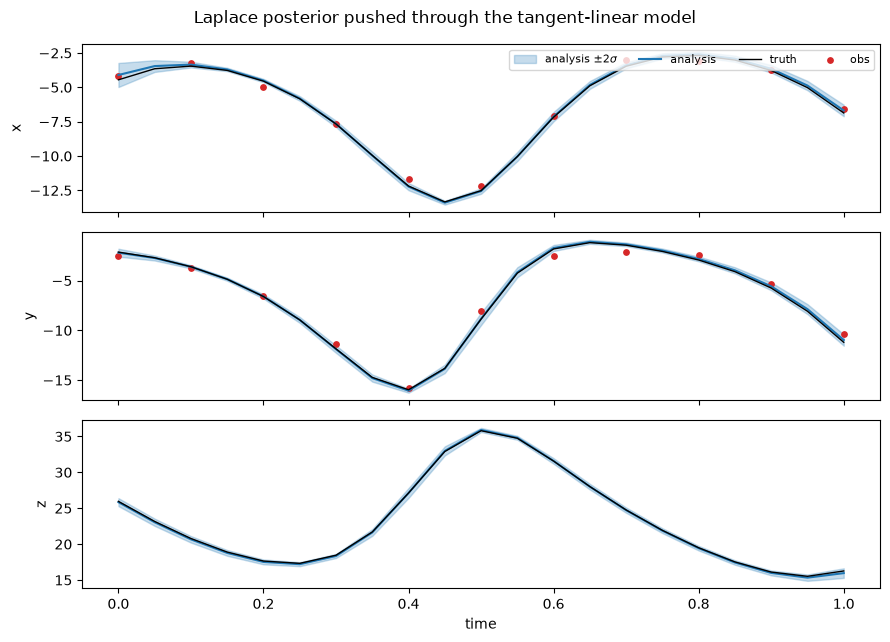

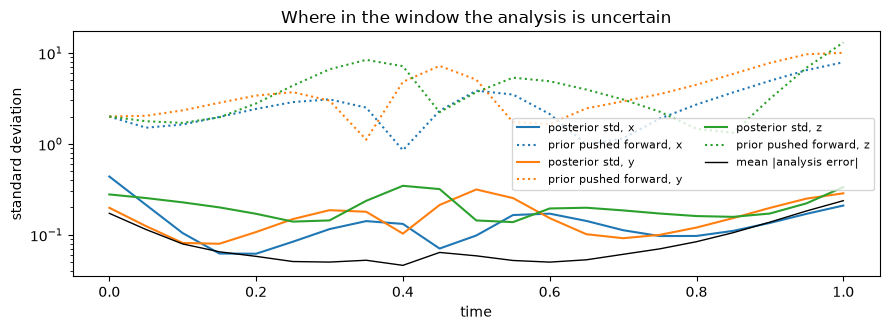

In [4]:
M_jac = jax.jacfwd(rollout)(x0_star)  # (T+1, 3, 3): M_t' along the analysis
M_jac_b = jax.jacfwd(rollout)(x_b)  # M_t' along the background forecast
cov_post_t = jnp.einsum("tij,jk,tlk->til", M_jac, P_laplace, M_jac)
cov_prior_t = jnp.einsum("tij,jk,tlk->til", M_jac_b, jnp.eye(3) * SIGMA_BG**2, M_jac_b)
std_post_t = jnp.sqrt(jnp.diagonal(cov_post_t, axis1=1, axis2=2))
std_prior_t = jnp.sqrt(jnp.diagonal(cov_prior_t, axis1=1, axis2=2))
traj_star = rollout(x0_star)

fig, axes = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.fill_between(ts, traj_star[:, i] - 2 * std_post_t[:, i], traj_star[:, i] + 2 * std_post_t[:, i], color="tab:blue", alpha=0.25, label=r"analysis $\pm 2\sigma$")
    ax.plot(ts, traj_star[:, i], color="tab:blue", label="analysis")
    ax.plot(ts, x_true[:, i], color="black", lw=1, label="truth")
    ax.scatter(ts, jnp.where(mask[:, i] == 1, y_obs[:, i], jnp.nan), color="tab:red", s=15, label="obs")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right", ncol=4, fontsize=8)
axes[-1].set_xlabel("time")
fig.suptitle("Laplace posterior pushed through the tangent-linear model")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
for i, name in enumerate(["x", "y", "z"]):
    ax.plot(ts, std_post_t[:, i], label=f"posterior std, {name}")
    ax.plot(ts, std_prior_t[:, i], linestyle=":", color=f"C{i}", label=f"prior pushed forward, {name}")
ax.plot(ts, jnp.abs(traj_star - x_true).mean(axis=1), color="black", lw=1, label="mean |analysis error|")
ax.set_yscale("log")
ax.set_xlabel("time")
ax.set_ylabel("standard deviation")
ax.legend(ncol=2, fontsize=8)
ax.set_title("Where in the window the analysis is uncertain")
plt.tight_layout()
plt.show()

The prior's push-forward grows through the window — that is chaos
amplifying an uncertain initial state. The posterior is smaller
everywhere, and shaped like a smoother's covariance: tightest in the
interior where observations sit on both sides, loosening toward the end
of the window where only the past constrains the state. The actual
error stays within the stated spread, which is the single-window
version of the calibration check in section 5.

## 4. Ensemble of data assimilations

Sixty-four members, each a full 4DVar with its own perturbed
observations and background. `EnsembleCovariance` returns the sample
covariance as a low-rank `gaussx` operator together with the members
themselves as `samples`.

ensemble mean            : [-4.0339 -2.2331 25.8894]   (MAP [-4.1024 -2.1912 25.8477])
posterior std, ensemble  : [0.4551 0.2045 0.3183]
posterior std, Laplace   : [0.4379 0.1984 0.2782]
provenance: {'adapter': 'EnsembleCovariance', 'n_members': 64, 'inflation': 1.0}


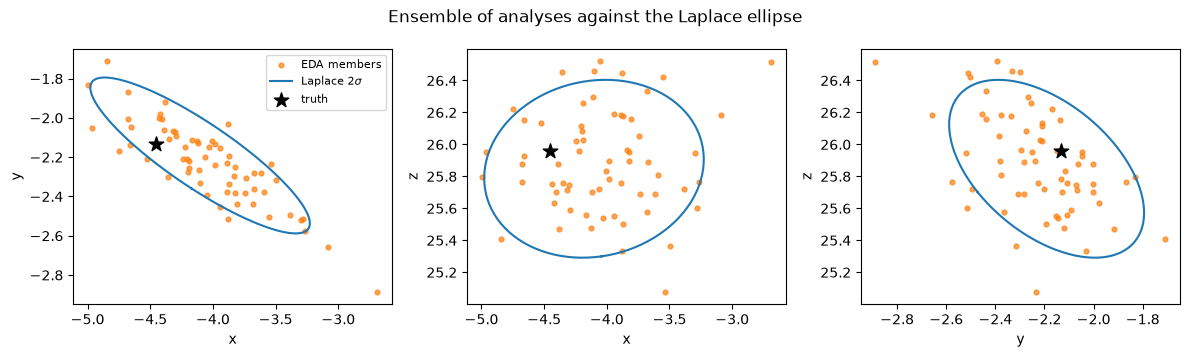

In [5]:
M_ENS = 64
k_eps, k_xi = jax.random.split(jax.random.PRNGKey(2))
eps = SIGMA_OBS * jax.random.normal(k_eps, (M_ENS, T + 1, 3)) * mask
xi = SIGMA_BG * jax.random.normal(k_xi, (M_ENS, 3))
members = jnp.stack([solve_map(y_obs + eps[m], mask, x_b + xi[m]) for m in range(M_ENS)])

post_ens = EnsembleCovariance(n_members=M_ENS)(members, model_view, batch=None)
P_ens = materialise(post_ens.cov, 3)
print("ensemble mean            :", post_ens.mean, f"  (MAP {x0_star})")
print("posterior std, ensemble  :", np.sqrt(np.diag(P_ens)))
print("posterior std, Laplace   :", np.sqrt(np.diag(P_laplace)))
print("provenance:", post_ens.provenance)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
pairs = [(0, 1), (0, 2), (1, 2)]
names = ["x", "y", "z"]
for ax, (i, j) in zip(axes, pairs):
    ax.scatter(members[:, i], members[:, j], s=12, color="tab:orange", alpha=0.7, label="EDA members")
    # 2-sigma ellipse of the Laplace posterior
    sub = P_laplace[jnp.ix_(jnp.array([i, j]), jnp.array([i, j]))]
    w, v = jnp.linalg.eigh(sub)
    theta = jnp.linspace(0, 2 * jnp.pi, 100)
    circ = jnp.stack([jnp.cos(theta), jnp.sin(theta)])
    ell = (v * (2 * jnp.sqrt(w))) @ circ
    ax.plot(x0_star[i] + ell[0], x0_star[j] + ell[1], color="tab:blue", label=r"Laplace $2\sigma$")
    ax.scatter([x_true[0, i]], [x_true[0, j]], marker="*", s=120, color="black", label="truth", zorder=3)
    ax.set_xlabel(names[i])
    ax.set_ylabel(names[j])
axes[0].legend(fontsize=8)
fig.suptitle("Ensemble of analyses against the Laplace ellipse")
plt.tight_layout()
plt.show()

The two estimates agree in scale and orientation; the ensemble cloud is
slightly curved where the Laplace ellipse is not, which is the
non-Gaussianity of a nonlinear model showing through. Sixty-four
members buy that at sixty-four times the cost, which is the trade-off
chapter 13 describes.

Whichever route produced it, a `Posterior` can be serialised for
downstream consumers with `GaussianMarkLikelihood`:

In [6]:
mark = GaussianMarkLikelihood(posterior=post_laplace, event_metadata={"window_start": 0.0, "notebook": 14})
summary = mark.to_dict()
print({k: (v if k != "cov_diag" else np.round(v, 4).tolist()) for k, v in summary.items() if k != "samples"})

{'mean': [-4.102412700653076, -2.191239595413208, 25.84772300720215], 'cov_diag': [0.1918, 0.0394, 0.0774], 'provenance': {'adapter': 'LaplaceCovariance', 'structure': 'strong_4dvar'}, 'event_metadata': {'window_start': 0.0, 'notebook': 14}}


## 5. Is the posterior calibrated?

Now the test that matters. Two hundred independent problems from the
generative model: $x_0 \sim \mathcal{N}(x_b, B)$ around a fixed
background on the attractor, observations simulated with the true
noise, a MAP and Laplace covariance for each. Everything is inside one
jitted function, so each problem costs a fraction of a second.

coverage of the 1-sigma interval per component: [0.64  0.67  0.625]  (nominal 0.683)
coverage of the 2-sigma interval per component: [0.96  0.94  0.935]  (nominal 0.954)
fraction with |z| > 3 per component            : [0. 0. 0.]  (nominal 0.003)
std of the z-scores per component             : [1.0341 1.0237 1.0605]  (nominal 1)


worst run: |z| = [2.9367 1.3816 0.1305], J(MAP) = 10.91, J(truth) = 15.87


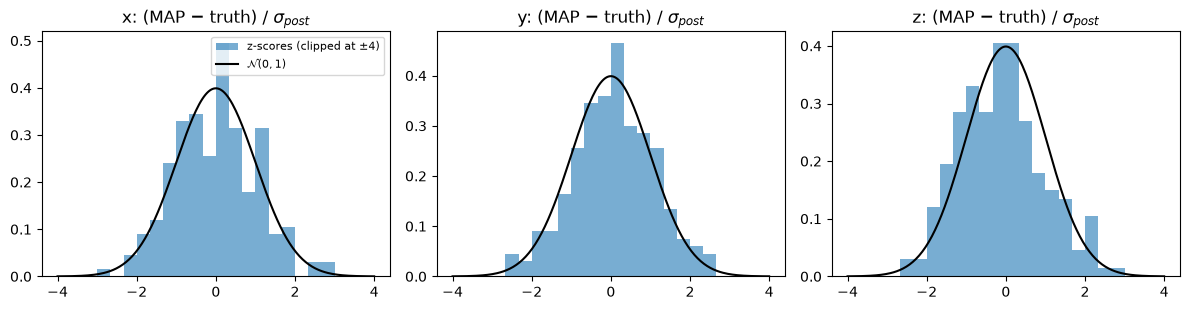

In [7]:
strong_fixed_bg = StrongFourDVar(
    forward=forward, obs_op=MaskedIdentity(), prior_mean=x_b,
    prior_cov_op=B_op, obs_cov_op=R_op, max_steps=300,
)


def gn_cov(x0, m):
    G = jax.jacfwd(lambda x: (m * rollout(x)).ravel())(x0)
    return jnp.linalg.inv(jnp.eye(3) / SIGMA_BG**2 + G.T @ G / SIGMA_OBS**2)


@jax.jit
def maps_and_covs(ys, ms):
    """Batched MAP + Gauss-Newton covariance for many windows sharing x_b."""
    x0 = strong_fixed_bg(Batch1D(input=ys, mask=ms))
    return x0, jax.vmap(gn_cov)(x0, ms)


def sample_prior(key):
    return x_b + SIGMA_BG * jax.random.normal(key, (3,))


def simulate_obs(x0, key):
    return (rollout(x0) + SIGMA_OBS * jax.random.normal(key, (T + 1, 3))) * mask


N_RUNS = 200
k_prior, k_obs_all = jax.random.split(jax.random.PRNGKey(3))
x0_true_runs = jax.vmap(sample_prior)(jax.random.split(k_prior, N_RUNS))
y_runs = jax.vmap(simulate_obs)(x0_true_runs, jax.random.split(k_obs_all, N_RUNS))
x0_runs, P_runs = maps_and_covs(y_runs, jnp.broadcast_to(mask, y_runs.shape))
sigma_runs = jnp.sqrt(jnp.diagonal(P_runs, axis1=1, axis2=2))
z_scores = (x0_runs - x0_true_runs) / sigma_runs

print("coverage of the 1-sigma interval per component:", jnp.mean(jnp.abs(z_scores) < 1.0, axis=0), " (nominal 0.683)")
print("coverage of the 2-sigma interval per component:", jnp.mean(jnp.abs(z_scores) < 2.0, axis=0), " (nominal 0.954)")
print("fraction with |z| > 3 per component            :", jnp.mean(jnp.abs(z_scores) > 3.0, axis=0), " (nominal 0.003)")
print("std of the z-scores per component             :", jnp.std(z_scores, axis=0), " (nominal 1)")
worst = int(jnp.argmax(jnp.max(jnp.abs(z_scores), axis=1)))
cost_runs = jax.vmap(lambda x0, y: 0.5 * jnp.sum((x0 - x_b) ** 2) / SIGMA_BG**2 + 0.5 * jnp.sum(((y - rollout(x0)) * mask) ** 2) / SIGMA_OBS**2)
print(f"worst run: |z| = {jnp.abs(z_scores[worst])}, J(MAP) = {float(cost_runs(x0_runs[worst:worst + 1], y_runs[worst:worst + 1])[0]):.2f}, "
      f"J(truth) = {float(cost_runs(x0_true_runs[worst:worst + 1], y_runs[worst:worst + 1])[0]):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
grid = jnp.linspace(-4, 4, 200)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.hist(np.asarray(jnp.clip(z_scores[:, i], -4, 4)), bins=24, range=(-4, 4), density=True, color="tab:blue", alpha=0.6, label="z-scores (clipped at $\\pm 4$)")
    ax.plot(grid, stats.norm.pdf(grid), color="black", label=r"$\mathcal{N}(0, 1)$")
    ax.set_title(f"{name}: (MAP $-$ truth) / $\\sigma_{{post}}$")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

The bulk is close to calibrated — the nominal intervals cover the truth
at near their nominal rates — but the tails are heavier than Gaussian:
one run in two hundred has standardised errors around ten, which a
Gaussian would never produce, and it alone lifts the standard deviation
of the $z$-scores visibly above one. Look at the cost in that run: the
MAP's cost is far *above* the truth's. The minimiser did not find the
global minimum; it converged to a local one, and the Laplace
approximation about the wrong mode is confidently wrong. Lorenz-63
windows that pass near the saddle at the origin or switch lobes have
sharply curved, sometimes bimodal, costs, and a quadratic expansion
about one minimum says nothing about the other. This is the failure
mode chapter 13 warns about ("unimodal-around-MAP only"). The cheap
defence is a multi-start; the principled one is an ensemble of analyses
or a sampler, either of which would have flagged the disagreement.

### Simulation-based calibration

The library gate, with posterior samples drawn from the Laplace Gaussian
via a Cholesky factor. The rank statistic is the $L^2$ norm of the state
(the function reduces to a scalar so that one histogram summarises the
vector case); a calibrated posterior gives uniform ranks on
$\{0, \ldots, n\}$. With $n = 99$ samples there are 100 possible ranks,
which ten bins split evenly; the shaded band is the 99 % interval a
uniform histogram of this size would stay within. Note what this test can and cannot see: a handful of tail
failures in one component barely move a norm-based rank histogram of a
hundred runs, so a pass here is necessary, not sufficient — which is
why the gates of chapter 14 are three, not one.

rank-histogram chi^2 = 9.4 on 9 dof (p = 0.40)


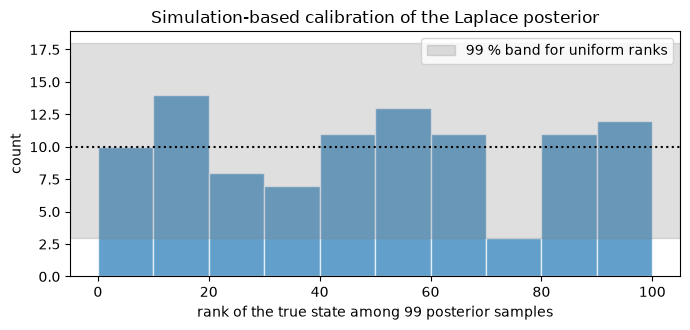

In [8]:
@jax.jit
def map_and_cov(y):
    x0 = strong_fixed_bg(Batch1D(input=y[None], mask=mask[None]))[0]
    return x0, gn_cov(x0, mask)


def sample_posterior(y, key, n):
    x0, P = map_and_cov(y)
    L = jnp.linalg.cholesky(P)
    return x0 + jax.random.normal(key, (n, 3)) @ L.T


N_RUNS_SBC, N_SAMPLES = 100, 99  # 100 possible ranks, so ten bins of ten
ranks = simulation_based_calibration(
    sample_posterior, sample_prior, simulate_obs,
    key=jax.random.PRNGKey(4), n_runs=N_RUNS_SBC, n_samples=N_SAMPLES,
)

n_bins = 10
counts, edges = np.histogram(np.asarray(ranks), bins=n_bins, range=(0, N_SAMPLES + 1))
expected = N_RUNS_SBC / n_bins
lo, hi = stats.binom.ppf([0.005, 0.995], N_RUNS_SBC, 1.0 / n_bins)
chi2 = float(np.sum((counts - expected) ** 2 / expected))
print(f"rank-histogram chi^2 = {chi2:.1f} on {n_bins - 1} dof (p = {1 - stats.chi2.cdf(chi2, n_bins - 1):.2f})")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color="tab:blue", alpha=0.7, edgecolor="white")
ax.axhspan(lo, hi, color="gray", alpha=0.25, label="99 % band for uniform ranks")
ax.axhline(expected, color="black", linestyle=":")
ax.set_xlabel(f"rank of the true state among {N_SAMPLES} posterior samples")
ax.set_ylabel("count")
ax.set_title("Simulation-based calibration of the Laplace posterior")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

- The Laplace posterior of a 4DVar analysis is the inverse Hessian of
  $J$; its Gauss–Newton form $(B^{-1} + G'^{\top}\mathcal{R}^{-1}G')^{-1}$
  uses the Jacobian of the *window* observation operator
  $G = (m_t \odot H M_t)_t$, and vardax's adapters build it lazily from
  any object exposing that operator through `linearize`.
- Pushing $P^*$ through $M_t'$ gives the uncertainty of every analysed
  state; it is a smoother's covariance, tight where observations
  surround the state and loose at the end of the window.
- An ensemble of perturbed analyses recovers the same covariance
  without derivatives, and some non-Gaussian structure besides, at $M$
  times the cost.
- Calibration is a property to be *tested*, not assumed: $z$-scores,
  interval coverage, and SBC rank histograms over many simulated
  windows. Here the Laplace posterior is calibrated in the bulk and
  over-confident in the tails, where the cost stops being quadratic.

Notebook [17](17_amortized_posterior_L63.ipynb) runs the same gates on an
amortized posterior, where they are far from a formality.